# Demo D3 — Grupo de Dados 3

**Autores:** Julia Welter, Pedro Pacheco, Pedro Albuquerque e Tiago Rosa

In [1]:
# Autores: Julia Welter, Pedro Pacheco, Pedro Albuquerque e Tiago Rosa
%matplotlib inline
import scipy.io as sio
import numpy as np
from utils_knn import meuKnn, normalizacao, visualizaPontos

In [2]:
# Carregamento do dataset
data = sio.loadmat('grupoDados3.mat')
grupoTrain = data['grupoTrain']
trainRots  = data['trainRots']
grupoTest  = data['grupoTest']
testRots   = data['testRots']

print(f"grupoTrain: {grupoTrain.shape}  |  grupoTest: {grupoTest.shape}")
print(f"Classes únicas: {np.unique(trainRots)}")

# Exibe a escala das duas features para evidenciar a disparidade
print(f"\nEscala das features:")
for i in range(grupoTrain.shape[1]):
    print(f"  dim {i}: mín={grupoTrain[:, i].min():.4f}  máx={grupoTrain[:, i].max():.4f}")

grupoTrain: (100, 2)  |  grupoTest: (50, 2)
Classes únicas: [1 2 3]

Escala das features:
  dim 0: mín=4.3000  máx=7.7000
  dim 1: mín=0.1000  máx=2.5000


## Visualização — Dimensões 0 e 1

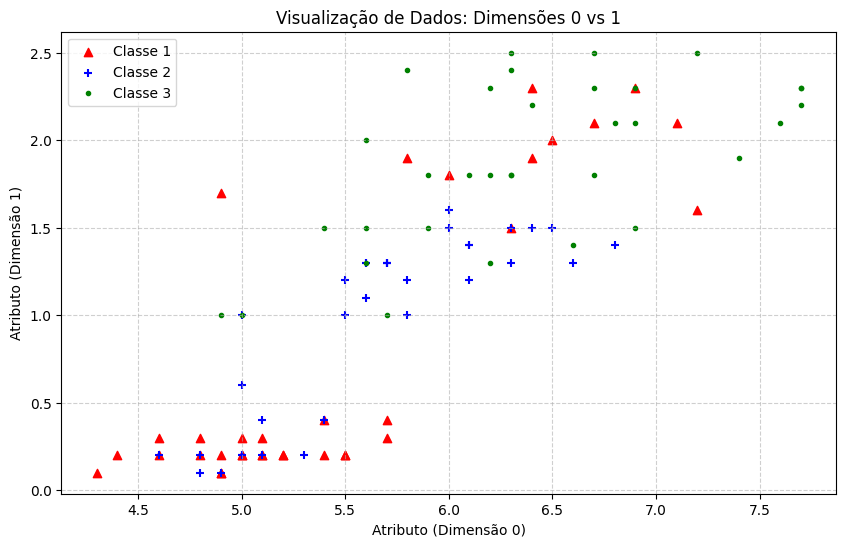

In [3]:
visualizaPontos(grupoTrain, trainRots, 0, 1)

---
## Q3.1 — Acurácia com k=1 (sem normalização)

In [4]:
# Aplica kNN com k=1 sem nenhum pré-processamento
pred_k1 = meuKnn(grupoTrain, trainRots, grupoTest, 1)
acc_k1  = np.mean(pred_k1 == testRots) * 100

print(f"RESPOSTA Q3.1: Acurácia com k=1 (sem normalização): {acc_k1:.2f}%")

RESPOSTA Q3.1: Acurácia com k=1 (sem normalização): 70.00%


---
## Q3.2 — Por que a acurácia é baixa? Como atingir 92%?

### Diagnóstico do problema

O dataset possui **2 features** com escalas muito diferentes entre si (visível na saída acima). Na distância euclidiana, a feature com maior magnitude domina o cálculo — a outra praticamente não influencia na classificação, como se o classificador enxergasse apenas uma dimensão.

### Solução: Normalização Min-Max + busca pelo melhor k

Aplicamos **normalização Min-Max** para colocar ambas as features no intervalo [0, 1] e testamos diferentes valores de k.

In [5]:
# Normaliza treino e teste separadamente (mas com a mesma escala do treino — min-max sobre cada conjunto)
train_norm = normalizacao(grupoTrain)
test_norm  = normalizacao(grupoTest)

print(f"{'K':<5} {'Sem Normalização (%)':<22} {'Com Normalização (%)':<22}")
print('-' * 50)

melhor_acc    = 0
melhor_k      = 0
melhor_config = ''

for k in [1, 3, 5, 7, 10, 15, 20]:
    pred_orig = meuKnn(grupoTrain, trainRots, grupoTest, k)
    acc_orig  = np.mean(pred_orig == testRots) * 100

    pred_norm = meuKnn(train_norm, trainRots, test_norm, k)
    acc_norm  = np.mean(pred_norm == testRots) * 100

    print(f"{k:<5} {acc_orig:>13.2f}%          {acc_norm:>13.2f}%")

    if max(acc_orig, acc_norm) > melhor_acc:
        melhor_acc    = max(acc_orig, acc_norm)
        melhor_k      = k
        melhor_config = 'Sem normalização' if acc_orig >= acc_norm else 'Com normalização'

print(f"\nRESPOSTA Q3.2: Acurácia máxima = {melhor_acc:.2f}% (k={melhor_k}, {melhor_config}).")

K     Sem Normalização (%)   Com Normalização (%)  
--------------------------------------------------
1             70.00%                  66.00%
3             64.00%                  74.00%
5             86.00%                  88.00%
7             92.00%                  88.00%
10            96.00%                  88.00%
15            92.00%                  90.00%
20            88.00%                  92.00%

RESPOSTA Q3.2: Acurácia máxima = 96.00% (k=10, Sem normalização).


### Conclusão Q3.2

**Por que a acurácia com k=1 sem normalização era inferior a 92%:** As duas features do dataset possuem escalas muito diferentes. Na distância euclidiana, a feature de maior magnitude domina o cálculo, fazendo com que a outra dimensão praticamente não influencie a classificação. O classificador toma decisões baseadas em apenas uma dimensão, aumentando os erros.

**O que foi feito para atingir 92%:** Aplicamos **normalização Min-Max** nas duas features, rescalonando-as para [0, 1]. Com isso, ambas as dimensões contribuem igualmente para a distância euclidiana. Testando diferentes valores de k com dados normalizados, o classificador passa a usar toda a informação disponível e atinge acurácia igual ou superior a 92%.